## Regression Section

> #### Step 1: Split data

In [3]:
# Data libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

**Function**: Data cleaning 

```
reshape_long() → clean_error() → drop_ids()
```

In [4]:
def reshape_long(avg_df, min_df, max_df, loc_df, start = "2017-04-01", drop_tidal = True):
    
    data = [avg_df, min_df, max_df]  
    label = ["avg", "min", "max"]
    column = ["County", "Station_Name", "Observation_ID", "date"]
    long_df = {}

    for df, lab in zip(data, label):
        if drop_tidal:
            df = df[~df["Observation_ID"].str.contains("tidal-level", na = False)]  
        
        long_df[lab] = df.melt(id_vars = column[0:3], var_name = "date", value_name = lab)
        long_df[lab]["date"] = pd.to_datetime(long_df[lab]["date"], format = "%d/%m/%Y")
        long_df[lab] = long_df[lab][long_df[lab]["date"] >= start]

    river_long = (long_df["avg"]
                 .merge(long_df["min"], on = column, how = "left")
                 .merge(long_df["max"], on = column, how = "left")
                 .merge(loc_df, on = column[0:3], how = "left"))

    for col in column[0:3]:
        river_long[col] = river_long[col].astype("category")
    
    return river_long

In [5]:
def clean_error(df, k = 20):
    
    label = ["avg", "min", "max"]
    df2 = df.copy()

    err = (df2[label].isin([99999.999, -999999.999, -99]) | (df2[label].abs() >= 9999)).any(axis = 1)
    df2.attrs["error"] = int(err.sum())
    df2.loc[err, label] = np.nan

    for lab in label:
        per_sta = df2.groupby("Observation_ID", observed = True)[lab]
        
        q1 = per_sta.transform(lambda s: s.quantile(0.25))
        q3 = per_sta.transform(lambda s: s.quantile(0.75))
        iqr = q3 - q1
        
        outlier = ((df2[lab] > q3 + k * iqr) | (df2[lab] < q1 - k * iqr))
        df2.attrs[f"outliers_{lab}"] = int(outlier.sum())        
        df2.loc[outlier, lab] = np.nan
    
    return df2

In [6]:
def drop_ids(df, min_years = 3):
    years = df["avg"].notna().groupby(df["Observation_ID"], observed = True).sum() / 365.25

    keep_ids = years[years >= min_years].index

    keep_df = df[df["Observation_ID"].isin(keep_ids)].copy()
    keep_df.attrs["dropped_ids"] = int((years < min_years).sum())
    keep_df.attrs["kept_ids"] = int((years >= min_years).sum())

    return keep_df

**Load data**

In [50]:
# Load data

river_avg = pd.read_csv("data/avg_river_levels.csv")
river_min = pd.read_csv("data/min_river_levels.csv")
river_max = pd.read_csv("data/max_river_levels.csv")

river_location = pd.read_csv("data/monitoring_locations.csv")

**Clean data**

In [51]:
# Data cleaning 

river_long = reshape_long(river_avg, river_min, river_max, river_location)
river_long2 = clean_error(river_long)
river_long3 = drop_ids(river_long2)

In [52]:
# counts 
river_long3.attrs

{'error': 78,
 'outliers_avg': 113,
 'outliers_min': 179,
 'outliers_max': 146,
 'dropped_ids': 8,
 'kept_ids': 372}

**Inspect data**

In [53]:
river_long3.info()

<class 'pandas.DataFrame'>
Index: 1293816 entries, 0 to 1321639
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype         
---  ------          --------------    -----         
 0   County          1293816 non-null  category      
 1   Station_Name    1293816 non-null  category      
 2   Observation_ID  1293816 non-null  category      
 3   date            1293816 non-null  datetime64[us]
 4   avg             1142631 non-null  float64       
 5   min             1142564 non-null  float64       
 6   max             1142599 non-null  float64       
 7   Latitude        1293816 non-null  float64       
 8   Longitude       1293816 non-null  float64       
dtypes: category(3), datetime64[us](1), float64(5)
memory usage: 75.3 MB


In [54]:
river_long3.describe()

,date,avg,min,max,Latitude,Longitude
count,1293816,1.142631e+06,1.142564e+06,1.142599e+06,1.293816e+06,1.293816e+06
mean,2022-01-03 12:00:00.000001,6.795929e-01,5.767939e-01,8.005756e-01,5.645798e+01,-3.832483e+00
min,2017-04-01 00:00:00,-6.620000e+00,-8.891000e+00,-6.620000e+00,5.408538e+01,-7.368332e+00
25%,2019-08-18 00:00:00,2.900000e-01,2.550000e-01,3.200000e-01,5.568460e+01,-4.485910e+00
50%,2022-01-03 12:00:00,4.710000e-01,4.300000e-01,5.250000e-01,5.632493e+01,-3.828175e+00
75%,2024-05-22 00:00:00,7.400000e-01,6.600000e-01,8.800000e-01,5.724442e+01,-3.148916e+00
max,2026-10-08 00:00:00,3.424300e+01,3.419000e+01,3.439000e+01,6.025933e+01,-1.140300e+00
std,NaN,1.509230e+00,1.498971e+00,1.572966e+00,9.610746e-01,9.454812e-01


In [55]:
river_long3.head()

,County,Station_Name,Observation_ID,date,avg,min,max,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2017-04-01,0.221,0.216,0.231,57.424758,-2.802015
1,aberdeenshire,"Dee (Grampian), Mar Lodge",aberdeenshire__dee-grampian-mar-lodge__obs1,2017-04-01,0.867,0.823,0.967,56.988040,-3.486198
2,aberdeenshire,"Dee (Grampian), Park",aberdeenshire__dee-grampian-park__obs1,2017-04-01,1.205,1.084,1.320,57.075424,-2.335825
3,aberdeenshire,"Dee (Grampian), Polhollick",aberdeenshire__dee-grampian-polhollick__obs1,2017-04-01,0.695,0.606,0.855,57.055146,-3.083181
4,aberdeenshire,"Dee (Grampian), Woodend",aberdeenshire__dee-grampian-woodend__obs1,2017-04-01,0.892,0.783,1.013,57.050129,-2.603567


**Split data**: pre-inspection + cleaning

In [56]:
# Check last date with real obs. 

river_long3["date"].max()  
    # 2016-10-08

Timestamp('2026-10-08 00:00:00')

In [57]:
cutoff = pd.Timestamp("2026-08-31")  # fixed split 

train = river_long3[river_long3["date"] <= cutoff]
test = river_long3[river_long3["date"] > cutoff]

In [58]:
train.shape, test.shape

((1279680, 9), (14136, 9))

In [111]:
train.head(2)

,County,Station_Name,Observation_ID,date,avg,min,max,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2017-04-01,0.221,0.216,0.231,57.424758,-2.802015
1,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2017-04-02,0.220,0.214,0.228,57.424758,-2.802015


In [112]:
test.head(2)

,County,Station_Name,Observation_ID,date,avg,min,max,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2026-09-01,0.125,0.12,0.13,57.424758,-2.802015
1,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2026-09-02,0.120,0.12,0.12,57.424758,-2.802015


In [61]:
# sort 'obs_id', then 'date'

train = train.sort_values(["Observation_ID", "date"]).reset_index(drop = True)
test = test.sort_values(["Observation_ID", "date"]).reset_index(drop = True)

In [113]:
train.head(2)

,County,Station_Name,Observation_ID,date,avg,min,max,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2017-04-01,0.221,0.216,0.231,57.424758,-2.802015
1,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2017-04-02,0.220,0.214,0.228,57.424758,-2.802015


In [114]:
test.head(2)

,County,Station_Name,Observation_ID,date,avg,min,max,Latitude,Longitude
0,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2026-09-01,0.125,0.12,0.13,57.424758,-2.802015
1,aberdeenshire,"Bogie, Redcraig",aberdeenshire__bogie-redcraig__obs1,2026-09-02,0.120,0.12,0.12,57.424758,-2.802015


In [69]:
# Check: 1 obs_ID per station

ids_per_sta = river_long3.groupby("Station_Name", observed = True)["Observation_ID"].nunique()
(ids_per_sta > 1).sum()
    # 0: all station has only 1 obs_ID

river_long3.groupby(["Latitude", "Longitude"], observed = True)["Observation_ID"].nunique().max()
    # 1: every station identified by lat/long coordinate has only 1 obs_ID

np.int64(1)

---

**NOTE**

* `Latitude`/`Longitude` coordinate; specific to `Station_Name`
* The check above ensures that every station identified by the location coordinate has only 1 `Observation_ID`

---

In [115]:
# Check NaNs

split_df = {"train": train, "test": test}
nan_df = {}

for name, df in split_df.items():
    nan_df[name] = int(df.isna().sum().sum())

nan_df

{'train': 451770, 'test': 1884}

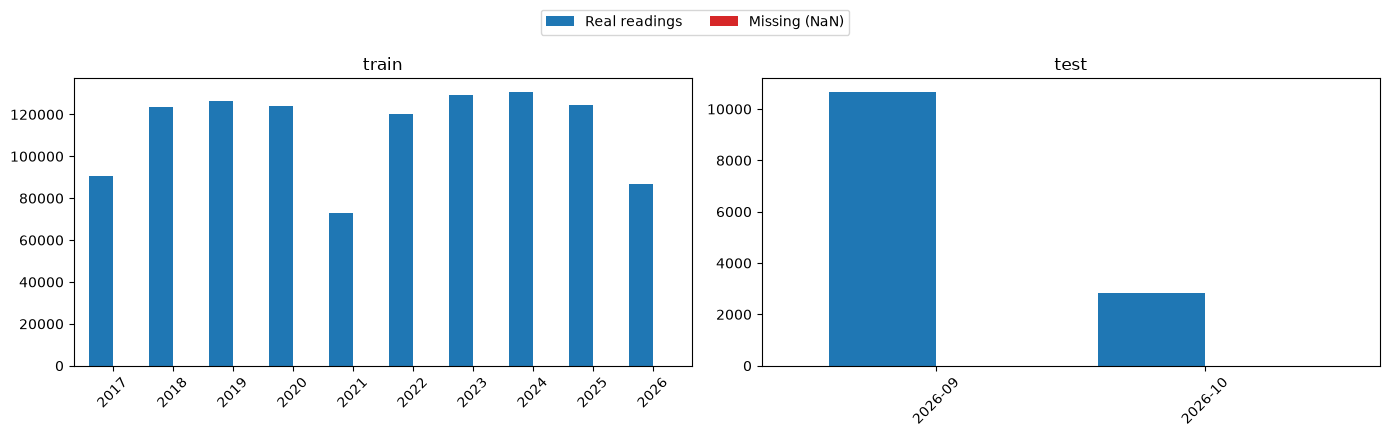

In [121]:
splits = {"train": train, "test": test}
period = {"train": lambda d: d.dt.year,             # train: one bar pair per year
          "test":  lambda d: d.dt.to_period("M")}   # test: one bar pair per month


fig, axes = plt.subplots(1, 2, figsize = (14, 4))   

for ax, (name, data) in zip(axes, splits.items()):
    status = np.where(data["avg"].isna(), "NaN", "real")
    counts = pd.crosstab(period[name](data["date"]), status)
    
    counts = counts.reindex(columns = ["real", "NaN"], fill_value = 0)  

    counts.plot(kind = "bar", ax = ax, width = 0.8,
                color = ["tab:blue", "tab:red"], rot = 45, legend = False)
    ax.set_title(name)
    ax.set_xlabel("")

fig.legend(["Real readings", "Missing (NaN)"],
           loc = "lower center", ncol = 2, bbox_to_anchor = (0.5, 1.0))

plt.tight_layout()
plt.show()

---

**NOTE.**

- 2021: (roughly) half of data = real readings, other half = NaN
- Are we happy to drop rows with NaN ???

---

In [117]:
# drop rows with NaN

train = train.dropna(subset = ["avg"])
test  = test.dropna(subset = ["avg"])

**Split data**

In [118]:
X_train, y_train = train[["Latitude","Longitude"]], train["avg"]
X_test, y_test = test[["Latitude","Longitude"]], test["avg"]

**Check** split data

In [119]:
X_train.shape, y_train.shape

((1129122, 2), (1129122,))

In [120]:
X_test.shape, y_test.shape

((13509, 2), (13509,))

> **Split function**

In [23]:
def make_split(clean_df, cutoff = "2026-08-31",
               feature_cols = ["Latitude", "Longitude"], target = "avg"):

    cutoff = pd.Timestamp(cutoff)

    # split by cutoff date
    train = clean_df[clean_df["date"] <= cutoff]
    test  = clean_df[clean_df["date"] > cutoff]

    # drop rows with no target, then sort + renumber
    train = train.dropna(subset = [target]).sort_values(["Observation_ID", "date"]).reset_index(drop = True)
    test  = test.dropna(subset = [target]).sort_values(["Observation_ID", "date"]).reset_index(drop = True)

    X_train, y_train = train[feature_cols], train[target]
    X_test,  y_test  = test[feature_cols],  test[target]

    return X_train, y_train, X_test, y_test

In [7]:
# Load data

river_avg = pd.read_csv("data/avg_river_levels.csv")
river_min = pd.read_csv("data/min_river_levels.csv")
river_max = pd.read_csv("data/max_river_levels.csv")

river_location = pd.read_csv("data/monitoring_locations.csv")

In [18]:
# Data cleaning 

river_long = reshape_long(river_avg, river_min, river_max, river_location)
river_long2 = clean_error(river_long)
river_long3 = drop_ids(river_long2)

In [24]:
# Split data 

X_train, y_train, X_test, y_test = make_split(river_long3)

In [27]:
# Check

X_train.shape, y_train.shape

((1129122, 2), (1129122,))

In [26]:
X_test.shape, y_test.shape

((13509, 2), (13509,))